In [1]:
root = "M://Diploma/experiments/vesuvius/fragments"

### Data overview

Downloaded file structure:
```
fragments/
    Frag1/
        inklabels.png
        ir.png
        mask.png
        surface_volume/
            00-64.tif
    Frag2/
    Frag3/
    Frag4/
```
Let's look at those examples to understand, what we will be working with.

The available data contains 4 fragments, with two more being a private evaluation dataset. Unfortunately, the latter part is not available publicly, which means we will not be able to fairly evaluate our solution in the same way as the competition did. Nonetheless, using Fragments 1-3 for training and Fragment 4 for evaluation should give a good enough estimate for this project.

In [2]:
fragments = list(range(1, 5))
depths = [0, 16, 32, 48, 64]

d:\Programs\Programming\Python\lib\site-packages\PIL\Image.py:3402: DecompressionBombWarning: Image size (140973980 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


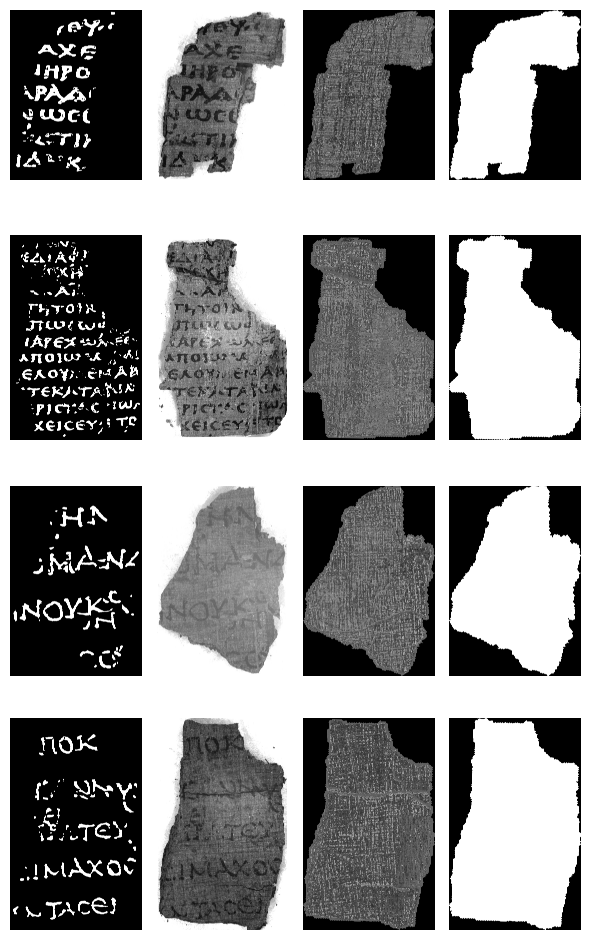

In [3]:
import PIL.Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(4, 4, figsize=(6, 10))
for fragment in fragments:
    # This is the target variable - segmentation masks, which we will be trying to predict
    axes[fragment - 1][0].imshow(PIL.Image.open(f"{root}/Frag{fragment}/inklabels.png"), cmap='gray')

    # Infrared scan. Not part of the competition's objective,
    # but may be useful as an easier version of the problem.
    # Unlike CT, in IR the ink is easily recognizable
    axes[fragment - 1][1].imshow(PIL.Image.open(f"{root}/Frag{fragment}/ir.png"), cmap='gray')

    # And the actual CT scans, which are the primary target of the competition.
    # 65 images per fragment, showing consequitive layers of the rollout fragment.
    # Basically a 3d -> 2d segmentation problem.
    axes[fragment - 1][2].imshow(PIL.Image.open(f"{root}/Frag{fragment}/surface_volume/32.tif"), cmap='gray')
    
    # The mask showing where the fragment is located in the image,
    # so that we do not process pixels outside the fragment
    axes[fragment - 1][3].imshow(PIL.Image.open(f"{root}/Frag{fragment}/mask.png"), cmap='gray')
for ax in axes.flat:
    ax.axis('off')
fig.tight_layout()
plt.show()

Infrared reveals clear letter shapes. CT, however, is dominated by papyrus texture, which makes it a much harder challenge. Fragment 3 also has visibly weaker IR contrast, so even that easier task will need to handle such differences.

In [4]:
import numpy

inklabels = numpy.array(PIL.Image.open(f"{root}/Frag1/inklabels.png"))
ir = numpy.array(PIL.Image.open(f"{root}/Frag1/ir.png"))
ct_layer = numpy.array(PIL.Image.open(f"{root}/Frag1/surface_volume/32.tif"))
mask = numpy.array(PIL.Image.open(f"{root}/Frag1/mask.png"))

print(inklabels.shape, inklabels.min(), inklabels.max())
print(ir.shape, ir.min(), ir.max())
print(ct_layer.shape, ct_layer.min(), ct_layer.max())
print(mask.shape, mask.min(), mask.max())

(8181, 6330) 0 1
(8181, 6330) 101 255
(8181, 6330) 0 65535
(8181, 6330) 0 1


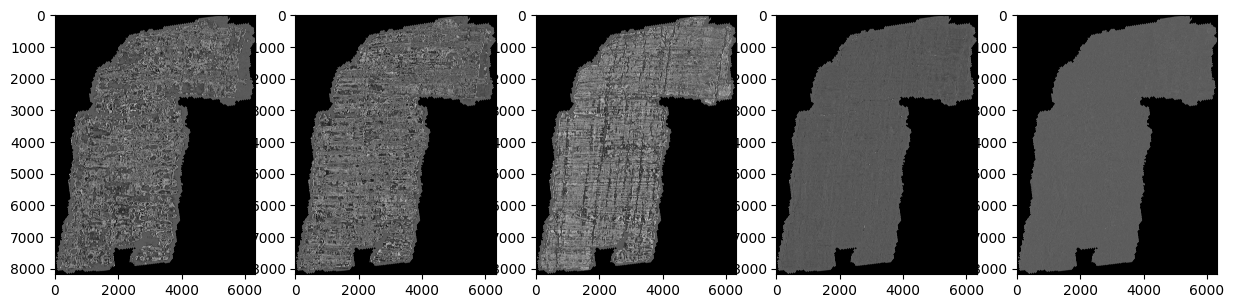

In [5]:
fig, axes = plt.subplots(1, 5, figsize = (15, 90))
axes[0].imshow(PIL.Image.open(f"{root}/Frag1/surface_volume/00.tif"), cmap='gray')
axes[1].imshow(PIL.Image.open(f"{root}/Frag1/surface_volume/15.tif"), cmap='gray')
axes[2].imshow(PIL.Image.open(f"{root}/Frag1/surface_volume/30.tif"), cmap='gray')
axes[3].imshow(PIL.Image.open(f"{root}/Frag1/surface_volume/45.tif"), cmap='gray')
axes[4].imshow(PIL.Image.open(f"{root}/Frag1/surface_volume/64.tif"), cmap='gray')

Layers 0, 15, and 30 have a clear pronounced texture, while layers 45 and 64 look almost uniform. Thus, bluntly combining the layers would probably hide useful structure, since each layer provides a different view on the material.

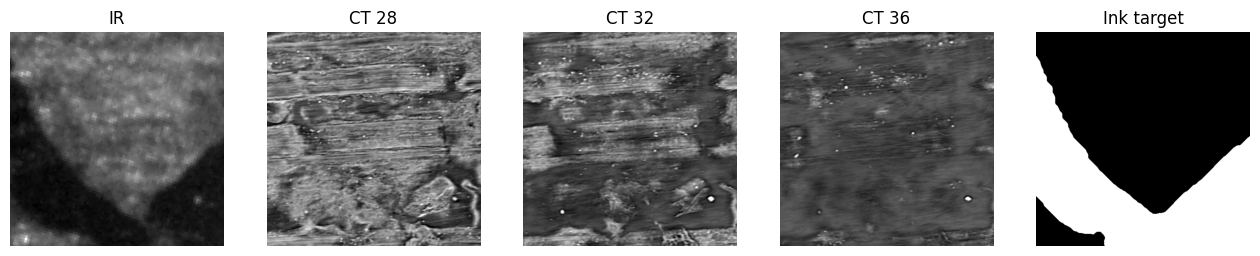

In [6]:
crop = numpy.s_[3793:4305, 2295:2807]
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
axes[0].imshow(ir[crop], cmap="gray")
axes[0].set_title("IR")
for ax, depth in zip(axes[1:4], [28, 32, 36]):
    with PIL.Image.open(root + "/Frag1" + f"/surface_volume/{depth:02d}.tif") as image:
        ax.imshow(numpy.array(image)[crop], cmap="gray")
    ax.set_title(f"CT {depth}")
axes[4].imshow(inklabels[crop] > 0, cmap="gray")
axes[4].set_title("Ink target")
for ax in axes:
    ax.axis("off")
plt.show()

In the example above, we are looking at a small fragment, and the ink is clearly recognizable here in both IR, and CT layer 32. However, CT 28 has only a fare-fetched barely visible silhouette dominated by fiber textures, and CT 36 arguably has nothing. Thus, we need our algorithm to accurately find the exact layers where ink is visible. Otherwise, the prediction is impossible.

### Data exploration

In [7]:
import pandas

summary = []
for fragment in fragments:
    mask = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/mask.png"))
    ink = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/inklabels.png"))
    assert mask.shape == ink.shape

    papyrus_pixels = numpy.count_nonzero(mask)
    ink_pixels = numpy.count_nonzero(mask & ink)
    summary.append({
        "fragment": fragment,
        "height": mask.shape[0],
        "width": mask.shape[1],
        "papyrus_pixels (mil.)": papyrus_pixels / 1e6,
        "ink_pixels (mil.)": ink_pixels / 1e6,
        "mask_coverage": papyrus_pixels / mask.size,
        "ink_fraction": ink_pixels / papyrus_pixels,
    })

summary = pandas.DataFrame(summary).set_index("fragment")
summary.round(3)

d:\Programs\Programming\Python\lib\site-packages\PIL\Image.py:3402: DecompressionBombWarning: Image size (140973980 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


,height,width,papyrus_pixels (mil.),ink_pixels (mil.),mask_coverage,ink_fraction
fragment,,,,,,
1,8181,6330,29.143,5.339,0.563,0.183
2,14830,9506,97.994,16.898,0.695,0.172
3,7606,5249,25.065,3.172,0.628,0.127
4,9791,6064,44.405,4.610,0.748,0.104


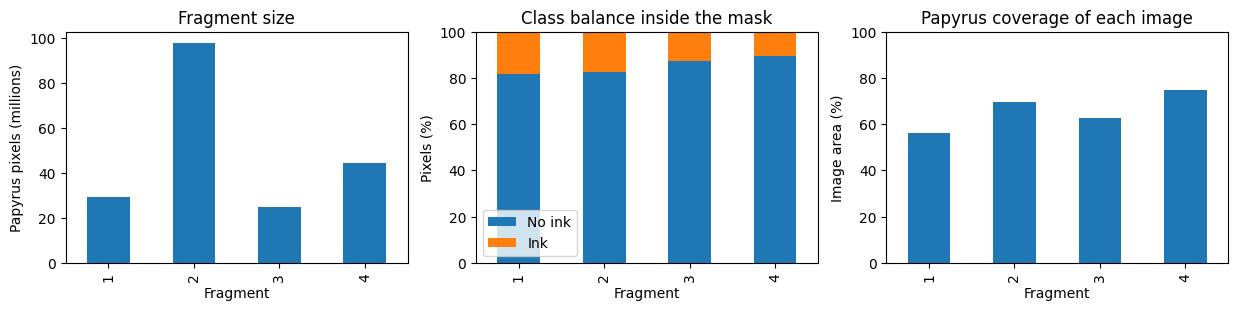

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3))

summary["papyrus_pixels (mil.)"].plot.bar(ax=axes[0])
axes[0].set(title="Fragment size", xlabel="Fragment", ylabel="Papyrus pixels (millions)")

balance = pandas.DataFrame({"No ink": 1 - summary["ink_fraction"], "Ink": summary["ink_fraction"]})
balance.mul(100).plot.bar(stacked=True, ax=axes[1])
axes[1].set(title="Class balance inside the mask", xlabel="Fragment", ylabel="Pixels (%)", ylim=(0, 100))

summary["mask_coverage"].mul(100).plot.bar(ax=axes[2])
axes[2].set(title="Papyrus coverage of each image", xlabel="Fragment", ylabel="Image area (%)", ylim=(0, 100))
plt.show()

A few observations from these results:
- Fragment 2 is much bigger than the rest, almost reaching 100 million pixels
- Every fragment has around 60-70% of pixels covered by the papyrus. Thus, accounting for the mask should be important not only to improving the accuracy, but also to the performance of the models: a significant fraction of pixels do not contain ink a priori.
- Expectedly, there are much less ink pixels than no-ink pixels. Thus, we will have a huge class imbalance to deal with, just like in most segmentation problems

d:\Programs\Programming\Python\lib\site-packages\PIL\Image.py:3402: DecompressionBombWarning: Image size (140973980 pixels) exceeds limit of 89478485 pixels, could be decompression bomb DOS attack.
  warnings.warn(


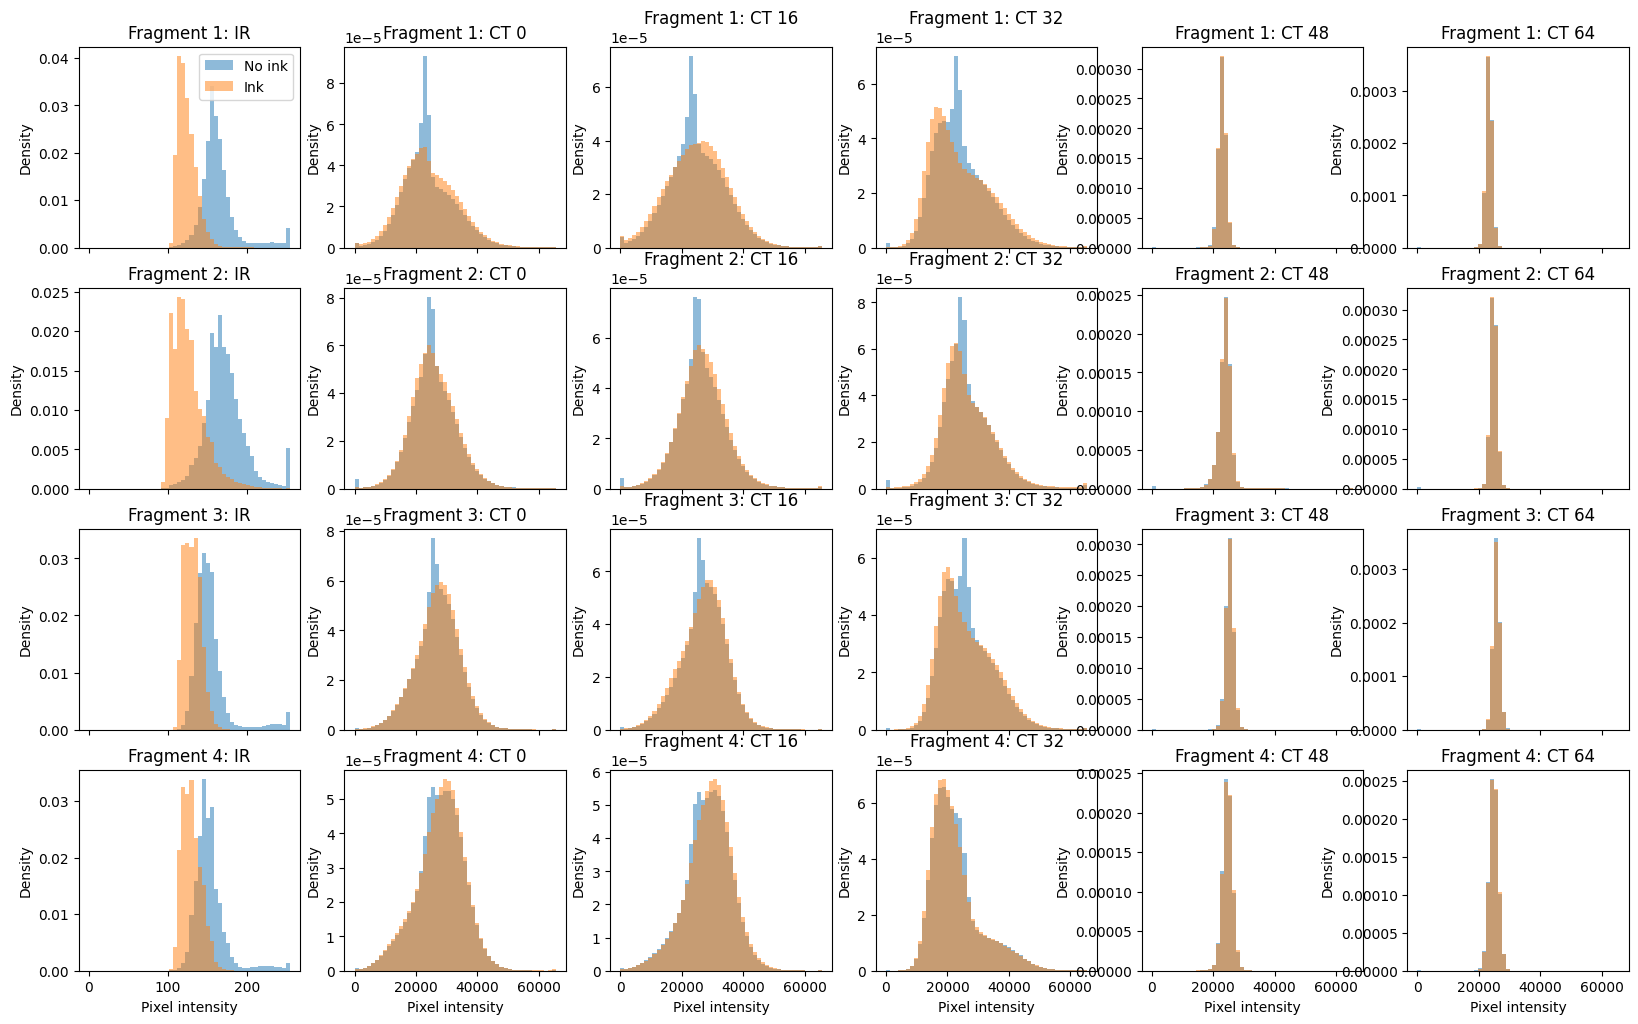

In [9]:
fig, axes = plt.subplots(4, 6, figsize=(20, 12), sharex="col")
for fragment in fragments:
    mask = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/mask.png")) > 0
    pixels = numpy.flatnonzero(mask)
    ink = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/inklabels.png")).ravel()[pixels] > 0

    files = [("IR", "ir.png", 255)] + [(f"CT {depth}", f"surface_volume/{depth:02d}.tif", 65535) for depth in depths]
    for column, (modality, filename, maximum) in enumerate(files):
        values = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/{filename}")).ravel()[pixels]
        for is_ink, label in [(False, "No ink"), (True, "Ink")]:
            axes[fragment - 1, column].hist(
                values[ink == is_ink],
                bins=numpy.linspace(0, maximum, 51),
                density=True,
                alpha=0.5,
                label=label
            )
        axes[fragment - 1, column].set(title=f"Fragment {fragment}: {modality}", ylabel="Density")
axes[0, 0].legend()
for ax in axes[-1]:
    ax.set_xlabel("Pixel intensity")
plt.show()

In infrared, the distributions of ink vs no-ink densitites are clearly different, which is what even a naked eye can see in the examples: ink is clearly darker in IR.

In CT, however, the distinction is much more subtle. The distributions almost precisely match, especially in the latter layers (48, 64), with only slight differences in the earlier ones. Thus, simple intensity thresholds will probably not be good enough for the task, and we need to account for spartial patterns and differences across depths.

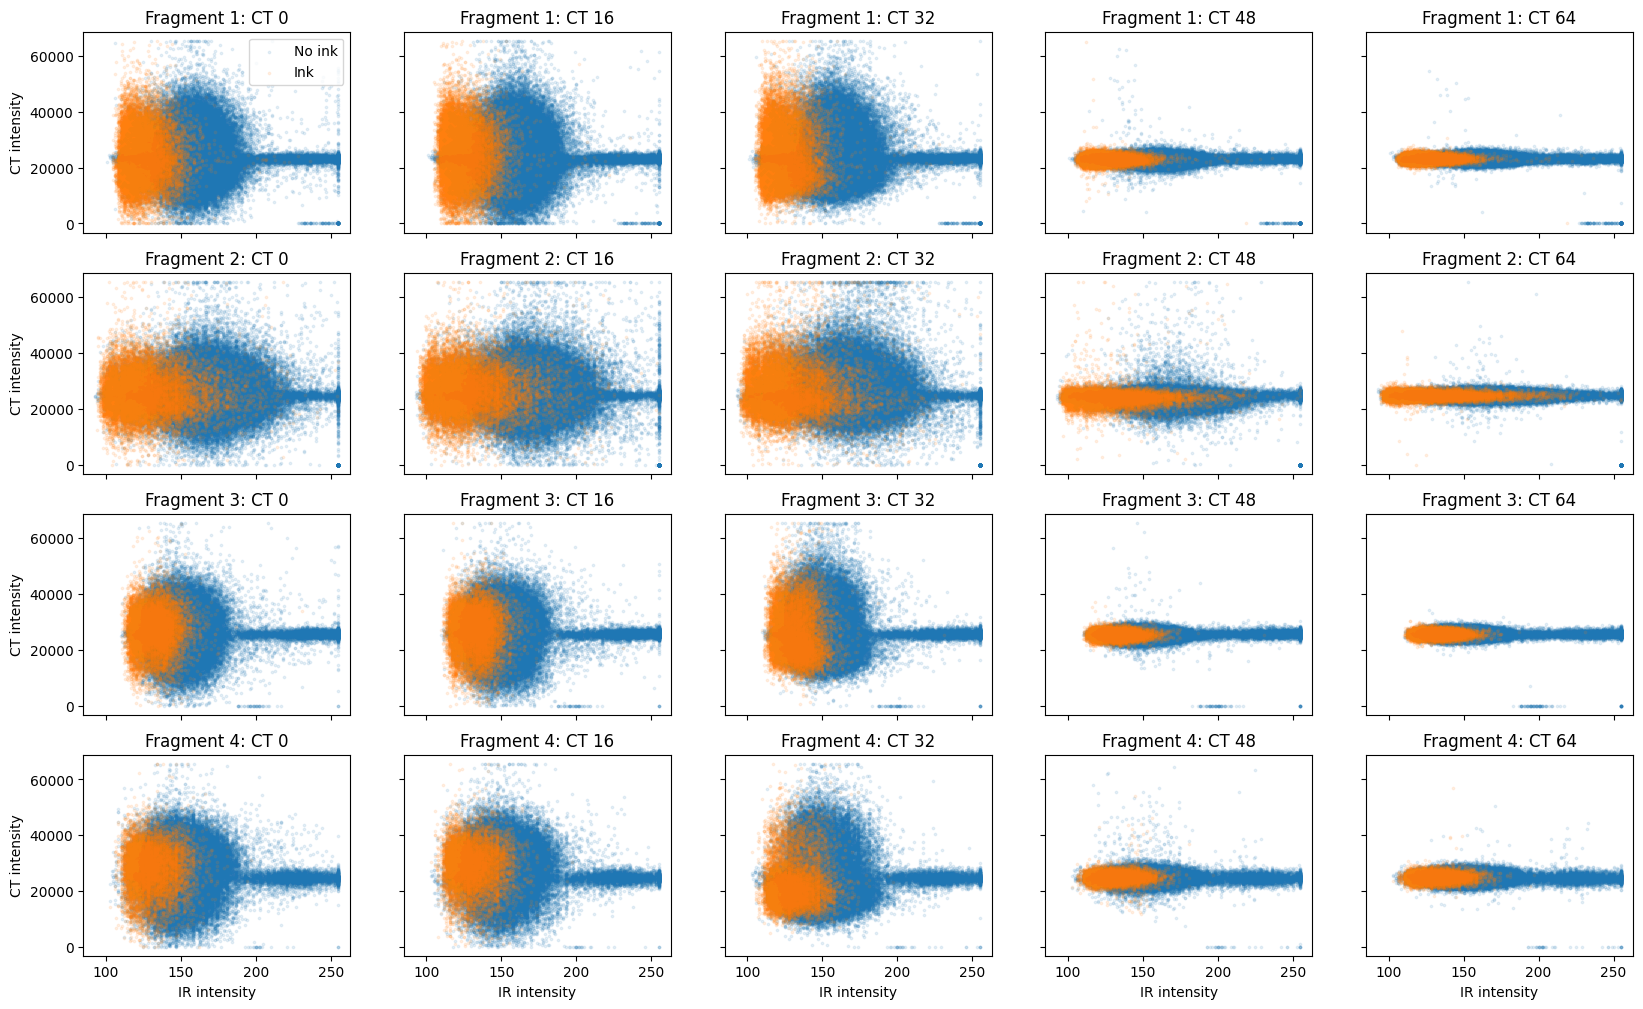

In [10]:
fig, axes = plt.subplots(4, len(depths), figsize=(20, 12), sharex=True, sharey=True)
for fragment in fragments:
    mask = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/mask.png"))
    pixels = numpy.random.choice(numpy.flatnonzero(mask), size=100000, replace=False)
    ink = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/inklabels.png")).ravel()[pixels] > 0
    ir = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/ir.png")).ravel()[pixels]

    for ax, depth in zip(axes[fragment - 1], depths):
        ct = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/surface_volume/{depth:02d}.tif")).ravel()[pixels]
        for is_ink, label in [(False, "No ink"), (True, "Ink")]:
            ax.scatter(ir[ink == is_ink], ct[ink == is_ink], s=3, alpha=0.1, label=label)
        ax.set_title(f"Fragment {fragment}: CT {depth}")
    axes[fragment - 1, 0].set_ylabel("CT intensity")
for ax in axes[-1]:
    ax.set_xlabel("IR intensity")
axes[0, 0].legend()
plt.show()

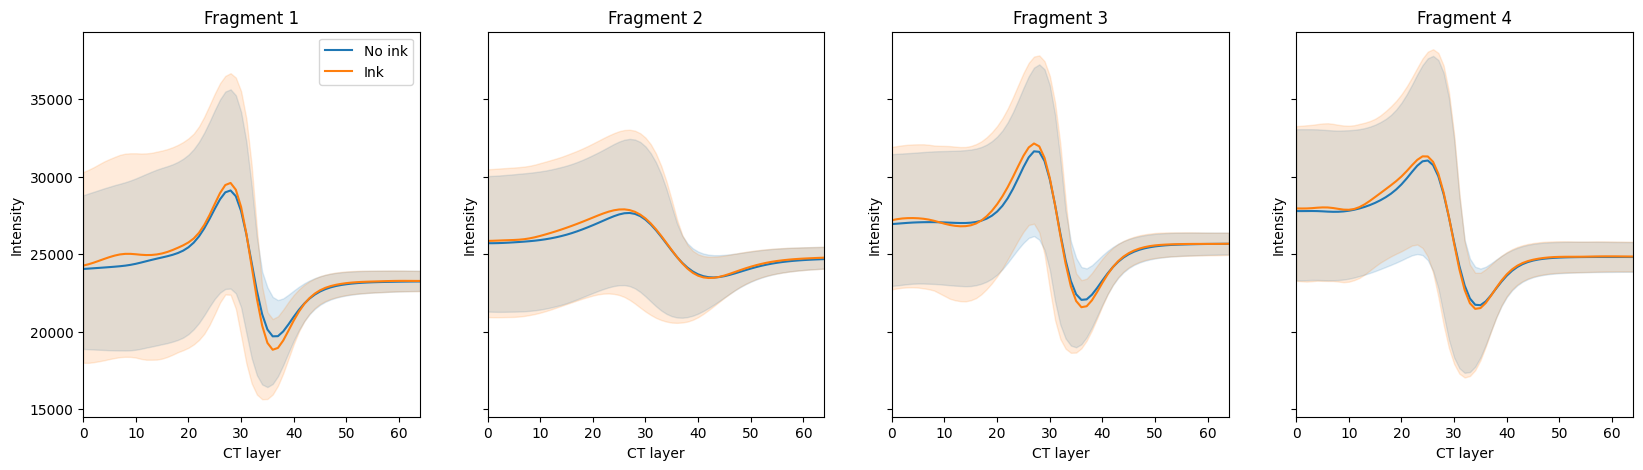

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)
for ax, fragment in zip(axes.flat, range(1, 5)):
    mask = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/mask.png"))
    pixels = numpy.flatnonzero(mask)
    ink = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/inklabels.png")).ravel()[pixels]

    ct = numpy.empty((len(pixels), 65), dtype=numpy.float32)
    for depth in range(65):
        ct[:, depth] = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/surface_volume/{depth:02d}.tif")).ravel()[pixels]

    for is_ink, label in [(False, "No ink"), (True, "Ink")]:
        values = ct[ink == is_ink]
        low, high = numpy.percentile(values, [25, 75], axis=0)
        line, = ax.plot(range(65), values.mean(axis=0, dtype=numpy.float64), label=label)
        ax.fill_between(range(65), low, high, color=line.get_color(), alpha=0.15)
    ax.set(title=f"Fragment {fragment}", xlabel="CT layer", ylabel="Intensity", xlim=(0, 64))
axes[0].legend()
plt.show()

All four fragments show an intensity peak around layer 25 for both ink and non-ink pixels, a trough at around layer 35, and a flat profile at other depths. This indicates the following:
- Layers 0 to 20 are the inside part of the papyrus
- Layers 20-40 are the edge, near the exposed writing surface
- Layers past 40 are the outward layers, most likely outisde the papyrus

Despite that ink and no-ink densities are very close to each other, the ink parts are slightly brighter before the peak and darker in the trough, which is an interesting observation that might be important for the modelling. Furthermore, this motivates preserving the layers explicitly, rather than using a full-depth mean.

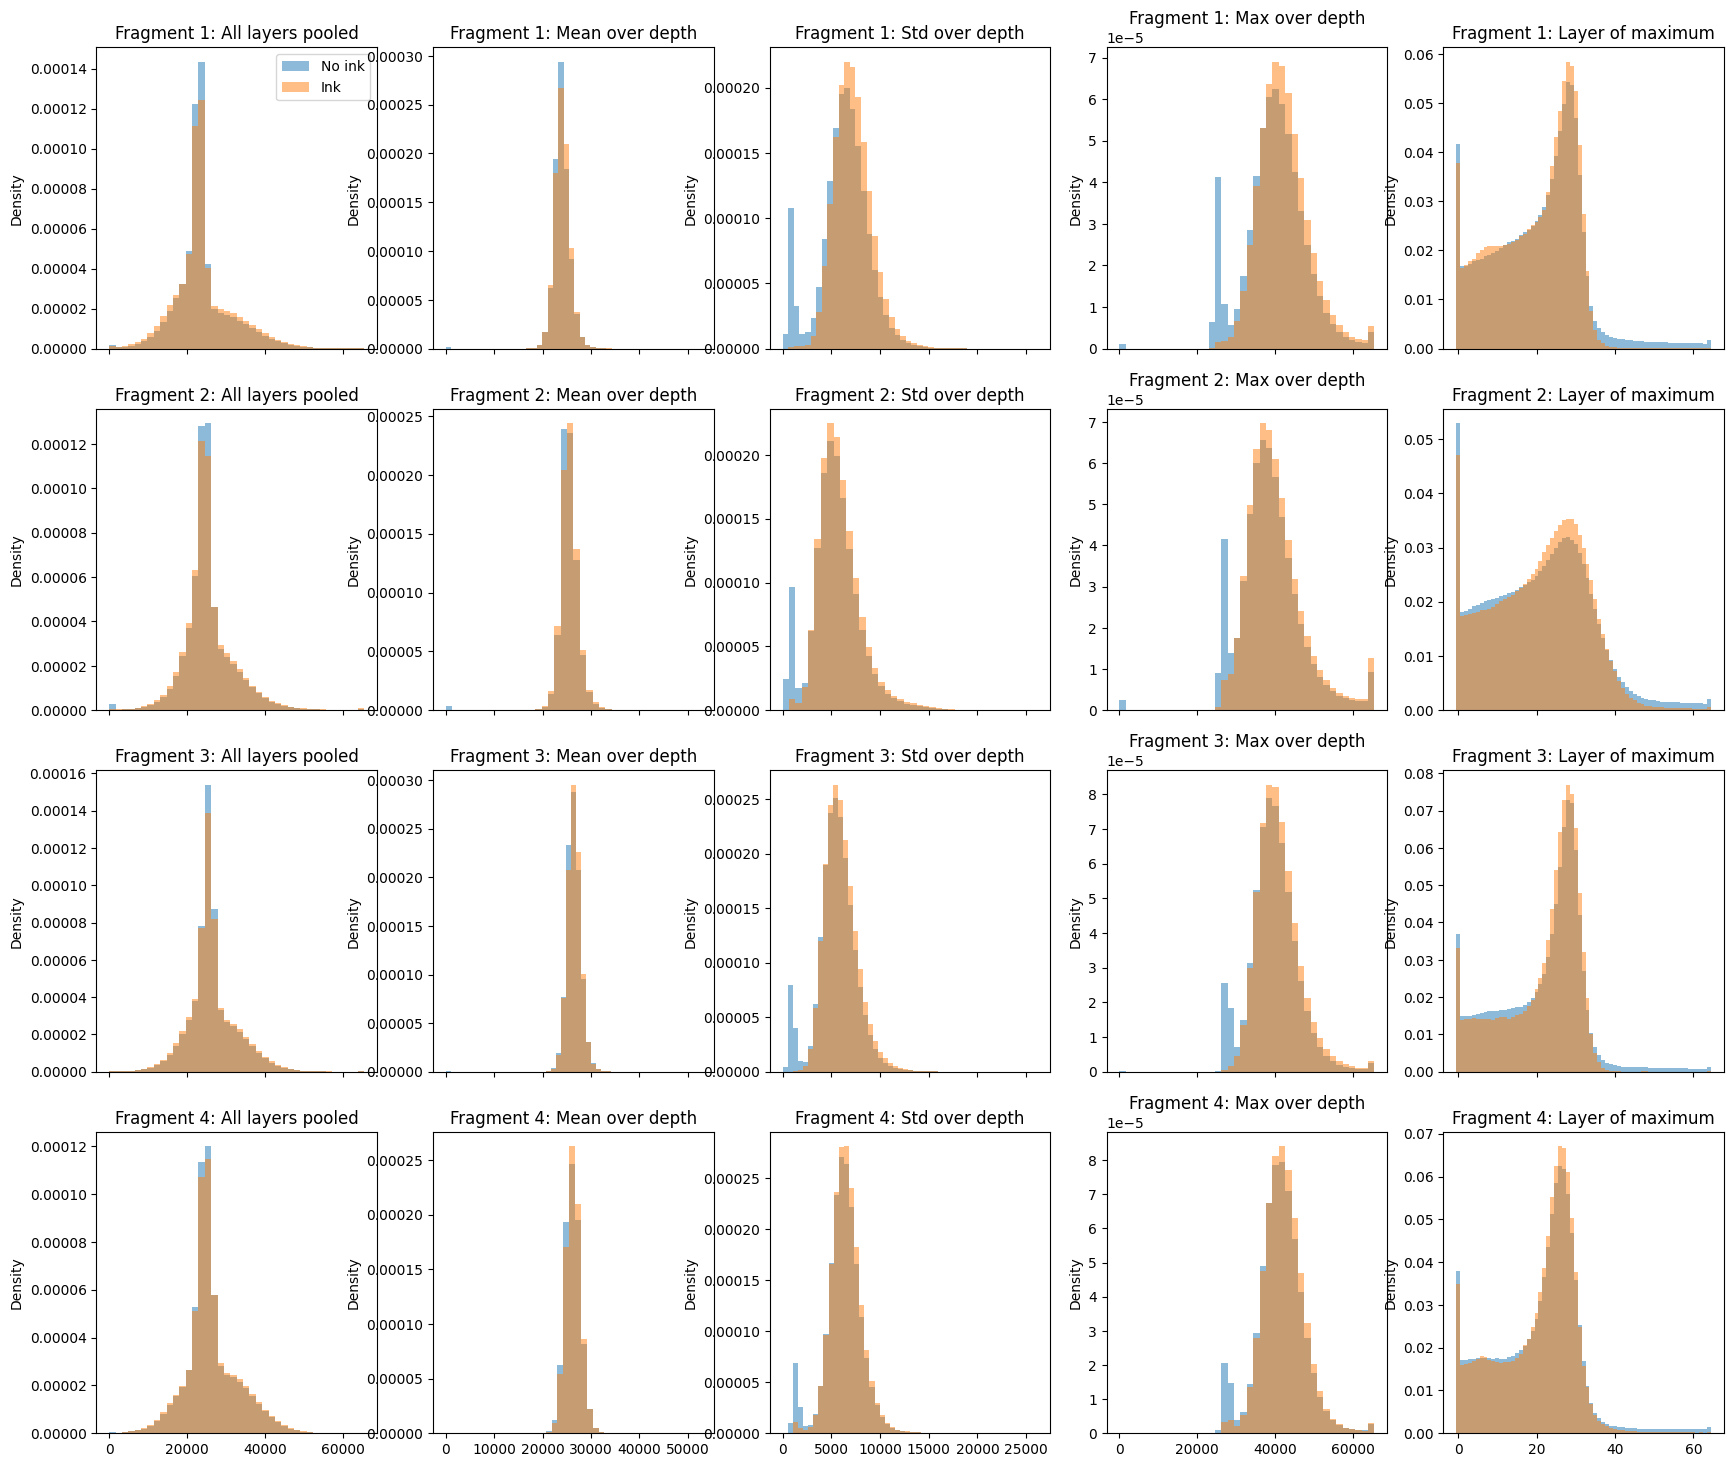

In [12]:
fig, axes = plt.subplots(4, 5, figsize=(21, 18), sharex="col")
for fragment in fragments:
    mask = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/mask.png"))
    pixels = numpy.flatnonzero(mask)
    ink = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/inklabels.png")).ravel()[pixels]

    ct = numpy.empty((len(pixels), 65), dtype=numpy.float32)
    for depth in range(65):
        ct[:, depth] = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/surface_volume/{depth:02d}.tif")).ravel()[pixels]

    summaries = [ct, ct.mean(axis=1), ct.std(axis=1), ct.max(axis=1), ct.argmax(axis=1)]
    titles = ["All layers pooled", "Mean over depth", "Std over depth", "Max over depth", "Layer of maximum"]
    for column, (title, values) in enumerate(zip(titles, summaries)):
        bins = numpy.arange(66) - 0.5 if title == "Layer of maximum" else numpy.histogram_bin_edges(values, bins=40)
        for is_ink, label in [(False, "No ink"), (True, "Ink")]:
            axes[fragment - 1, column].hist(values[ink == is_ink].ravel(), bins=bins, density=True, alpha=0.5, label=label)
        axes[fragment - 1, column].set(title=f"Fragment {fragment}: {title}", ylabel="Density")
axes[0, 0].legend()
plt.show()

Aggregating all layer intensities produces almost identical class distributions. STD and maximum retain more differencies, but the distinction is still weak. These summaries are worth testing as simple features, but the results argue against expecting good predictions.

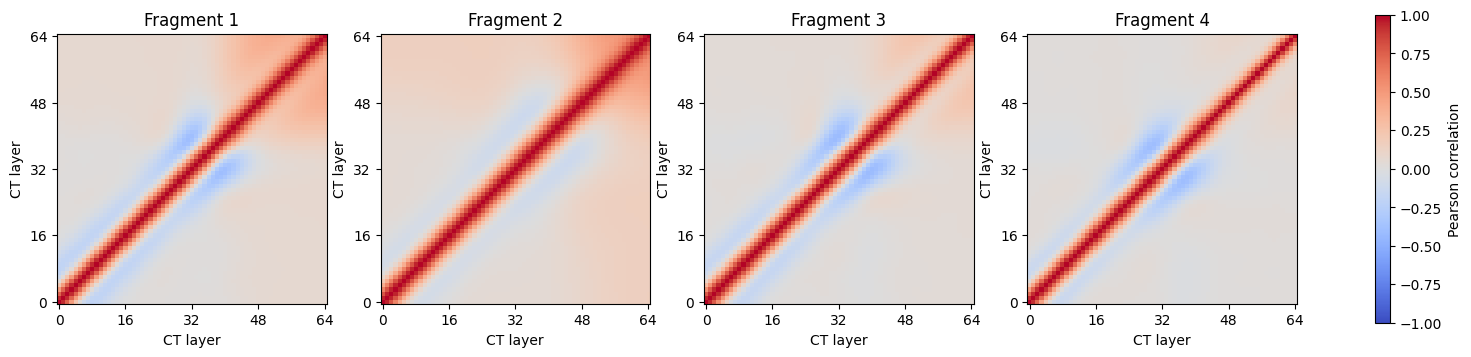

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for ax, fragment in zip(axes.flat, fragments):
    mask = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/mask.png"))
    pixels = numpy.random.choice(numpy.flatnonzero(mask), size=10000000, replace=False)
    ink = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/inklabels.png")).ravel()[pixels]

    ct = numpy.empty((len(pixels), 65), dtype=numpy.float32)
    for depth in range(65):
        ct[:, depth] = numpy.array(PIL.Image.open(f"{root}/Frag{fragment}/surface_volume/{depth:02d}.tif")).ravel()[pixels]

    correlation = numpy.corrcoef(ct, rowvar=False)
    ax.set_facecolor("lightgray")
    plot = ax.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1, origin="lower")
    ax.set(
        title=f"Fragment {fragment}", xlabel="CT layer", ylabel="CT layer", xticks=[0, 16, 32, 48, 64], yticks=[0, 16, 32, 48, 64]
    )
fig.colorbar(plot, ax=axes, label="Pearson correlation", shrink=0.8)
plt.show()

The narrow red diagonal indicates that neighboring layers are strongly correlated, while layers farther apart are often independent. Interestingly, there are also noticeable blue regions, revaling negative correlations between some layers on opposite sides of the central transition.